# 14 · Interpretabilidad con SHAP

**Fase CRISP-DM:** 5. Evaluación

**Objetivo:** entender **por qué** LightGBM ordena como ordena, y comprobar que aprendió **por las razones correctas**.

**SHAP** reparte el puntaje de cada platillo entre sus features: puntaje = valor base + una contribución por feature. Una contribución positiva empuja el platillo **hacia arriba** en la lista. Se usa el TreeSHAP **nativo** de LightGBM, que es exacto para árboles y entiende las categóricas (canónico, tipo de plato).

**La ventaja de simular:** se sabe exactamente cómo eligió cada persona (`simulation/choice.py`). Eso permite contrastar el modelo con la verdad en tres cosas (no en magnitudes, porque SHAP mide el modelo y no la utilidad):

1. **Signo:** ¿cada feature empuja hacia donde debería?
2. **Orden:** ¿las razones que más pesan en la verdad son las que más pesan en el modelo?
3. **Forma:** por ejemplo, el picante solo debería castigar **por encima** de lo que la persona tolera.

**Datos:** 3,000 consultas de validación al azar (unos 17,000 platillos candidatos).

> Este notebook solo narra el algoritmo. La lógica vive en `src/puzzle_recsys`.

## Configuración

In [1]:
import json

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap

from puzzle_recsys.catalog.library import load_library
from puzzle_recsys.config import load_paths, load_simulation, load_yaml
from puzzle_recsys.eda.multivariate import latent_diner_traits
from puzzle_recsys.explainability.ground_truth_check import (
    observed_signs,
    true_components,
    truth_items,
    within_query_spread,
)
from puzzle_recsys.explainability.shap_analysis import (
    group_importance,
    plot_dependence,
    relative_to_query,
    top_reasons,
    tree_shap,
)
from puzzle_recsys.ranking.feature_sets import FOR_YOU
from puzzle_recsys.ranking.lgbm_ranker import to_lgbm
from puzzle_recsys.repository.parquet_repo import ParquetRepository, run_id_for
from puzzle_recsys.simulation.distributions import make_rng

paths, sim = load_paths(), load_simulation()
SEED = sim.seed
repo = ParquetRepository(paths.synthetic / run_id_for(sim.run_name, sim.seed))
meta = json.loads((paths.models / "lgbm_meta.json").read_text(encoding="utf-8"))["para_ti"]
lgbm = lgb.Booster(model_file=str(paths.models / "lgbm_para_ti.txt"))
ti = pd.read_parquet(paths.data_model / "para_ti.parquet")
valid = ti[ti["split"] == "valid"]
del ti
qs = make_rng(SEED, "shap_sample").choice(valid["query_id"].unique(), 3_000, replace=False)
muestra = valid[valid["query_id"].isin(set(qs))]
data = to_lgbm(muestra, FOR_YOU, meta["categories"])
X = data.X
filas = muestra.loc[X.index]  # mismo orden que X
valores, base = tree_shap(lgbm, X)
# En un ranking solo cuenta lo que distingue a un candidato de los demás de SU consulta.
rel = relative_to_query(valores, data.query_id)
num_cols = [c for c in X.columns if c not in (*FOR_YOU.categorical, *FOR_YOU.target_encoded)]
X_rel = relative_to_query(X[num_cols].astype(float), data.query_id)
pd.Series({"consultas": len(qs), "candidatos": len(X), "features": X.shape[1],
           "chequeo: SHAP suma al puntaje": bool(np.allclose(valores.sum(axis=1) + base, lgbm.predict(X, raw_score=True)))},
          name="valor").to_frame().T

C:\Users\natal\Cundinamarca\Puzzle\Recomendador\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,consultas,candidatos,features,chequeo: SHAP suma al puntaje
valor,3000,17670,33,True


## 1. SHAP global

**Dos importancias distintas, y en un ranking importa la segunda:**

- **Global** (media de |SHAP|): cuánto mueve una feature el puntaje en promedio.
- **Para el orden** (media de |SHAP relativo a la consulta|): cuánto **distingue** a un platillo de los otros de la misma consulta. Una feature igual para todos los candidatos (el ticket habitual de la persona, sus visitas) sube o baja el puntaje de **todos** por igual: puede tener SHAP global alto y **no cambiar el orden en nada**.

Como varias features dicen casi lo mismo (SHAP reparte el crédito entre ellas de forma algo arbitraria), también se reporta la importancia **por grupo** de features con el mismo significado.

,global,para el orden
share_restaurante,0.400,0.334
canonical_pred,0.243,0.207
share_proteina,0.273,0.181
log_veces_pidio_canonico,0.216,0.156
afinidad_cocina_platillo,0.157,0.101
log_dias_en_menu,0.247,0.088
log_pedidos_previos_platillo,0.079,0.048
franja,0.043,0.039
dif_picante_declarado,0.055,0.038
log_veces_pidio_platillo,0.042,0.036


,global,para el orden
historia de la persona con el platillo,0.332,0.332
popularidad,0.326,0.323
qué platillo es,0.193,0.204
onboarding,0.060,0.052
contexto,0.034,0.038
precio,0.026,0.027
perfil general (igual para toda la consulta),0.028,0.024


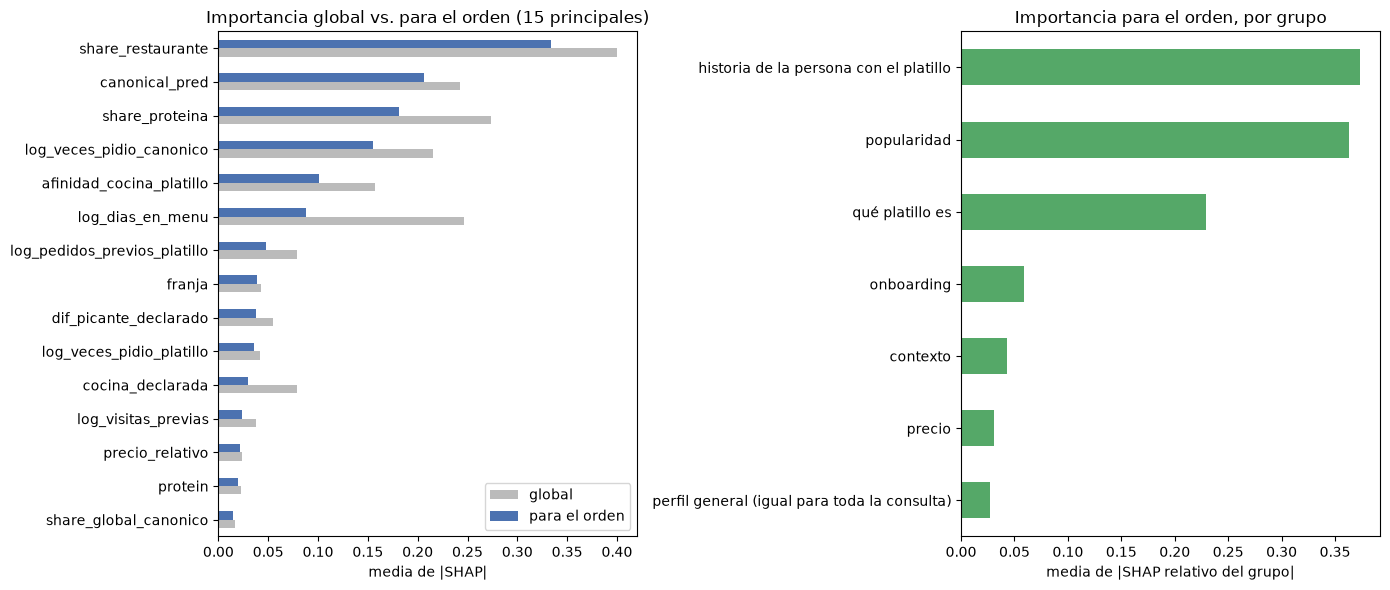

In [2]:
imp = pd.DataFrame({"global": valores.abs().mean(), "para el orden": rel.abs().mean()}).sort_values("para el orden", ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
imp.head(15).iloc[::-1].plot.barh(ax=axes[0], color=["#BBBBBB", "#4C72B0"])
axes[0].set_title("Importancia global vs. para el orden (15 principales)"); axes[0].set_xlabel("media de |SHAP|")
grupos = {
    "qué platillo es": ["canonical_pred", "course", "protein", "cocina_platillo", "spice_level", "is_shareable"],
    "popularidad": ["share_restaurante", "share_global_canonico", "log_pedidos_previos_platillo",
                    "log_pedidos_previos_restaurante", "log_dias_en_menu"],
    "precio": ["log_precio", "precio_relativo", "ajuste_precio"],
    "historia de la persona con el platillo": ["log_veces_pidio_canonico", "log_veces_pidio_platillo", "share_proteina",
                                               "afinidad_cocina_platillo", "dif_picante"],
    "onboarding": ["picante_declarado", "dif_picante_declarado", "cocina_declarada", "onboarding_completo"],
    "perfil general (igual para toda la consulta)": ["habito_tipo", "picante_medio", "log_ticket_medio", "tasa_compartir",
                                                     "dias_desde_ultima", "log_visitas_previas"],
    "contexto": ["franja", "fin_de_semana", "pax", "n_candidatos"],
}
assert sorted(sum(grupos.values(), [])) == sorted(X.columns), "cada feature en un solo grupo"
gimp = group_importance(rel, grupos)
gimp.iloc[::-1].plot.barh(ax=axes[1], color="#55A868")
axes[1].set_title("Importancia para el orden, por grupo"); axes[1].set_xlabel("media de |SHAP relativo del grupo|")
fig.tight_layout(); fig.savefig(paths.figures / "14_importancia_shap.png", dpi=150)
display(imp.head(15).round(3))
pd.DataFrame({"global": group_importance(valores, grupos) / group_importance(valores, grupos).sum(),
              "para el orden": gimp / gimp.sum()}).sort_values("para el orden", ascending=False).round(3)

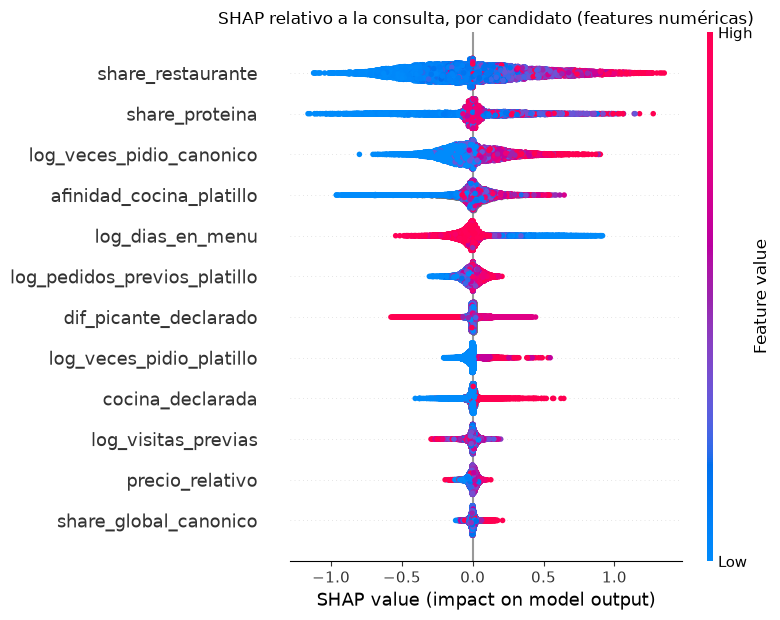

In [3]:
# Beeswarm: cada punto es un candidato; el color es el valor de la feature (rojo = alto).
num = [c for c in imp.index if c in num_cols][:12]
shap.summary_plot(rel[num].to_numpy(), X[num].astype(float), show=False, max_display=12)
plt.title("SHAP relativo a la consulta, por candidato (features numéricas)")
plt.tight_layout(); plt.savefig(paths.figures / "14_beeswarm.png", dpi=150)

## 2. Dependencias

Cómo cambia la contribución **relativa a la consulta** de una feature según su valor. La línea roja es la media por tramo.

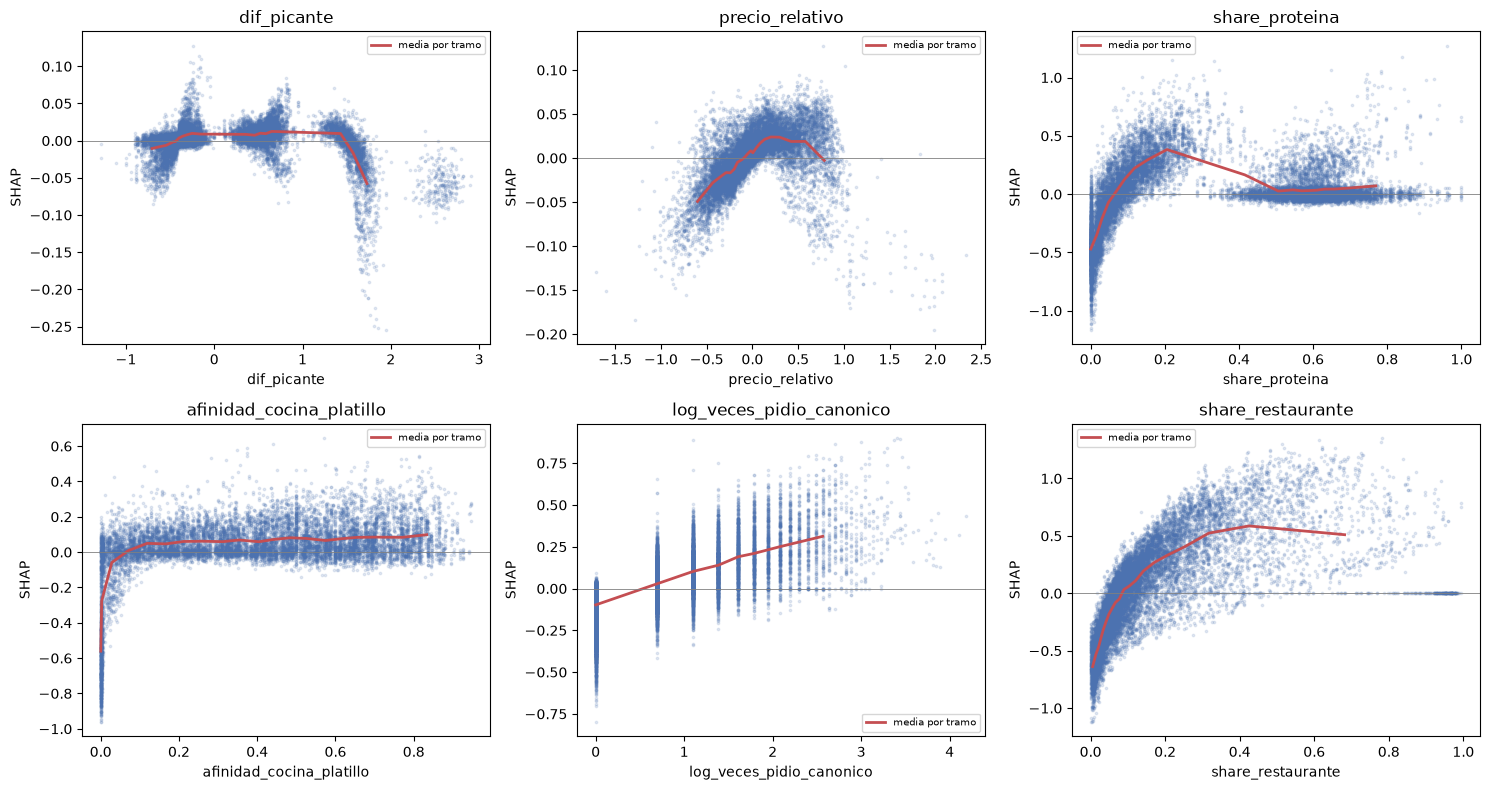

In [4]:
dep = ["dif_picante", "precio_relativo", "share_proteina", "afinidad_cocina_platillo", "log_veces_pidio_canonico", "share_restaurante"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for col, ax in zip(dep, axes.ravel()):
    plot_dependence(X[col], rel[col], title=col, ax=ax)
fig.tight_layout(); fig.savefig(paths.figures / "14_dependencias.png", dpi=150)

## 3. Contraste con la verdad

### 3.1 Signo

Para cada feature con una dirección esperada según cómo se simuló la elección, se compara contra la dirección que aprendió el modelo **dentro de la consulta**: Spearman entre la feature y su SHAP, ambos relativos al promedio de la consulta.

- Las features del **perfil general** (hábito, picante y ticket habituales, visitas) son iguales para todos los candidatos de una consulta: su efecto esperado en el orden es **nulo**.
- `dif_picante` no va aquí: su efecto esperado no es una dirección sino una **bisagra** (sección 3.3).

In [5]:
esperado = {
    "share_restaurante": ("+", "atractivo y calidad del platillo (lo bueno se pide más)"),
    "share_global_canonico": ("+", "atractivo del canónico en toda la plataforma"),
    "log_pedidos_previos_platillo": ("+", "atractivo y calidad"),
    "share_proteina": ("+", "afinidad por la proteína"),
    "afinidad_cocina_platillo": ("+", "afinidad por la cocina"),
    "log_veces_pidio_canonico": ("+", "no está en la utilidad: es un reflejo de los gustos estables"),
    "dif_picante_declarado": ("-", "castigo por picante (con lo declarado)"),
    "spice_level": ("-", "a más picante, más personas fuera de su tolerancia"),
    "habito_tipo": ("0", "igual para toda la consulta"),
    "picante_medio": ("0", "igual para toda la consulta"),
    "log_ticket_medio": ("0", "igual para toda la consulta"),
    "log_visitas_previas": ("0", "igual para toda la consulta"),
}
obs = observed_signs(rel[list(esperado)], X_rel[list(esperado)]).set_index("feature")
signos = pd.DataFrame({"esperado": {k: v[0] for k, v in esperado.items()},
                       "por qué": {k: v[1] for k, v in esperado.items()}}).join(obs)
signos["¿coincide?"] = signos["esperado"] == signos["signo"]
display(signos[["esperado", "signo", "rho", "¿coincide?", "por qué"]].round(3))
pd.Series({"coincidencias": f"{signos['¿coincide?'].sum()} de {len(signos)}"}).to_frame("valor").T

,esperado,signo,rho,¿coincide?,por qué
share_restaurante,+,+,0.930,True,atractivo y calidad del platillo (lo bueno se ...
share_global_canonico,+,+,0.348,True,atractivo del canónico en toda la plataforma
log_pedidos_previos_platillo,+,+,0.953,True,atractivo y calidad
share_proteina,+,+,0.693,True,afinidad por la proteína
afinidad_cocina_platillo,+,+,0.650,True,afinidad por la cocina
log_veces_pidio_canonico,+,+,0.968,True,no está en la utilidad: es un reflejo de los g...
dif_picante_declarado,-,-,-0.155,True,castigo por picante (con lo declarado)
spice_level,-,-,-0.500,True,"a más picante, más personas fuera de su tolera..."
habito_tipo,0,0,-0.002,True,igual para toda la consulta
picante_medio,0,0,0.002,True,igual para toda la consulta


,coincidencias
valor,12 de 12


### 3.2 Orden

Con la verdad oculta se reconstruyen las piezas de la utilidad **verdadera** de cada candidato: cocina, proteína, ingredientes, picante y atractivo + calidad. La pieza que más **varía entre los candidatos de una consulta** es la que más decide qué se pide. Se compara ese orden contra la importancia SHAP del grupo de features que observa cada pieza.

El precio no entra: su pieza depende de un "precio ideal" de cada persona que no se reconstruye aquí; se revisa por su forma (sección 2).

In [6]:
library = load_library(paths.external / "canonical_dishes.yaml")
cuisines = sorted(repo.read_table("restaurants")["cuisine_pred"].unique())
gt = repo.ground_truth
menu = repo.read_table("menu_items").merge(gt.read_table("menu_items"), on="menu_item_id")
menu = menu[menu["menu_item_id"].isin(set(filas["menu_item_id"]))]
items = truth_items(
    menu,
    repo.read_table("canonical_dishes").set_index("canonical_id")["cuisine"],
    repo.read_table("menu_item_attributes").query("kind == 'ingredient'"),
    gt.read_table("canonical_appeal").set_index("canonical_id")["appeal"],
    gt.read_table("menu_item_quality").set_index("menu_item_id")["quality"],
    cuisines=cuisines,
    ingredient_names=list(library.ingredients),
)
ids = pd.Index(filas["diner_id"].unique())
tastes = latent_diner_traits(gt.read_table("diner_tastes"), gt.read_table("duplicate_accounts"), ids, cuisines)
verdad = true_components(filas, tastes, items, sim.choice)
spread = within_query_spread(verdad, ["cocina", "proteina", "ingredientes", "picante", "atractivo_calidad"])

observa = {
    "cocina": ["afinidad_cocina_platillo", "cocina_platillo", "cocina_declarada"],
    "proteina": ["share_proteina", "protein"],
    "picante": ["dif_picante", "dif_picante_declarado", "spice_level"],
    "atractivo_calidad": ["canonical_pred", "share_restaurante", "share_global_canonico",
                          "log_pedidos_previos_platillo", "log_pedidos_previos_restaurante"],
    "ingredientes": [],
}
orden = pd.DataFrame({
    "variación en la verdad (dentro de la consulta)": spread,
    "importancia SHAP del grupo que la observa": pd.Series({k: group_importance(rel, {k: v})[k] if v else np.nan
                                                           for k, v in observa.items()}),
})
orden["rango verdad"] = orden.iloc[:, 0].rank(ascending=False)
orden["rango modelo"] = orden.iloc[:, 1].rank(ascending=False)
display(orden.sort_values("rango verdad").round(3))
comparable = orden.dropna()
from scipy.stats import spearmanr
pd.Series({"ρ de Spearman entre los dos órdenes (sin ingredientes)": spearmanr(comparable["rango verdad"], comparable["rango modelo"])[0]},
          name="valor").round(3).to_frame()

,variación en la verdad (dentro de la consulta),importancia SHAP del grupo que la observa,rango verdad,rango modelo
cocina,1.523,0.127,1.0,3.0
atractivo_calidad,0.621,0.536,2.0,1.0
proteina,0.430,0.180,3.0,2.0
picante,0.184,0.048,4.0,4.0
ingredientes,0.128,NaN,5.0,NaN


,valor
ρ de Spearman entre los dos órdenes (sin ingredientes),0.4


### 3.3 Forma: el picante solo castiga por encima de lo tolerado

En la verdad, un platillo **menos** picante que lo que la persona tolera no suma ni resta, y cada nivel **por encima** resta 1.2 puntos de utilidad (una bisagra). Si el modelo aprendió bien, la contribución de `dif_picante` (picante del platillo menos el que la persona suele pedir) debería ser casi plana a la izquierda de 0 y caer a la derecha.

In [7]:
d = pd.DataFrame({"dif": X["dif_picante"], "shap": rel["dif_picante"]}).dropna()
d["tramo"] = pd.cut(d["dif"], [-3.5, -1.5, -0.5, 0.5, 1.5, 3.5], labels=["≤ -2", "-1", "0", "+1", "≥ +2"])
forma = d.groupby("tramo", observed=True)["shap"].agg(["mean", "size"]).rename(columns={"mean": "SHAP medio", "size": "candidatos"})
forma.round(3)

,SHAP medio,candidatos
tramo,,
-1,-0.007,3192
0,0.005,8422
+1,0.011,4282
≥ +2,-0.037,1774


## 4. Lectura de negocio: por qué se recomienda lo que se recomienda

Un ejemplo concreto, como se vería en Puzzle: una persona **con historial** abre el menú de plato fuerte. Para cada platillo se muestra su lugar en la lista y las tres razones que más lo **distinguen de los demás platillos del menú** (SHAP relativo a la consulta): positivas lo suben, negativas lo bajan.

In [8]:
nombres = repo.read_table("menu_items").set_index("menu_item_id")["name"]
candidatas = filas[(filas["course"] == "MAIN") & (filas["visitas_previas"] >= 20)]
tam = candidatas.groupby("query_id").size()
ejemplo_q = tam[tam.between(5, 7)].index[0]
fila_q = filas["query_id"] == ejemplo_q
ej = filas[fila_q].assign(puntaje=lgbm.predict(X[fila_q.to_numpy()], raw_score=True))
ej = ej.sort_values("puntaje", ascending=False)
contrib = rel[fila_q.to_numpy()].loc[ej.index]

pd.DataFrame({"lugar": range(1, len(ej) + 1), "platillo": ej["menu_item_id"].map(nombres).to_numpy(),
              "¿lo pidió?": np.where(ej["y"] == 1, "sí", ""), "puntaje": ej["puntaje"].round(2).to_numpy(),
              "razones principales (SHAP relativo)": [top_reasons(contrib.loc[i]) for i in ej.index]})

,lugar,platillo,¿lo pidió?,puntaje,razones principales (SHAP relativo)
0,1,Tlacoyo de frijol especial,sí,-1.11,"share_proteina (+0.56), share_restaurante (+0...."
1,2,Gorditas de chicharrón,,-1.34,"share_proteina (+0.57), canonical_pred (-0.12)..."
2,3,Huarache con bistec especial,,-1.84,"canonical_pred (+0.41), share_proteina (-0.24)..."
3,4,Quesadilla especial,,-2.02,"share_restaurante (+0.39), canonical_pred (-0...."
4,5,Sopes,,-2.68,"share_proteina (-0.31), share_restaurante (-0...."
5,6,Quesadilla de tinga de pollo,,-3.01,"share_restaurante (-0.52), share_proteina (-0...."


## Conclusiones

### 1. En un ranking, la importancia que cuenta es "para el orden"

La primera versión de este análisis usó el SHAP global y daba lecturas engañosas: features iguales para toda la consulta (ticket habitual, número de visitas) aparecían con efecto, y la explicación del ejemplo mostraba solo razones negativas. **Esas features suben o bajan el puntaje de todos los candidatos por igual y no cambian el orden.** La corrección fue medir el SHAP **relativo a la consulta**. Con él:

| Grupo | Importancia para el orden |
|---|---|
| Historia de la persona con el platillo | 33 % |
| Popularidad | 32 % |
| Qué platillo es | 20 % |
| Onboarding | 5 % |
| Contexto (franja, día) | 4 % |
| Precio | 3 % |
| Perfil general | 2 % |

La decisión se reparte entre **lo que la persona ya mostró que le gusta** y **lo que a todos les gusta en ese lugar**, con el platillo en sí como tercer pilar.

### 2. Signo: 12 de 12 coinciden con la verdad

Dentro de cada consulta, todas las features con dirección esperada empujan hacia donde deben: popularidad, proteína habitual, afinidad por la cocina y haber pedido antes el canónico suben el platillo; más picante lo baja; y el perfil general no mueve el orden (ρ ≈ 0). La popularidad global del canónico tiene un efecto más débil (ρ = 0.35) porque el modelo ya identifica el canónico directamente y le da ese crédito a él: es el reparto entre variables correlacionadas que se anticipó en la propuesta.

### 3. Forma: el picante funciona como bisagra, corrida a la derecha

Con picante igual o menor al habitual, la contribución es casi nula (de -0.007 a +0.011). Con **2 o más niveles por encima** cae (-0.037). Es la bisagra de la verdad, pero corrida: la persona tolera **más** picante del que suele pedir, así que el castigo empieza más arriba de su promedio pedido. El modelo lo aprendió solo, sin que se le dijera dónde está el quiebre.

### 4. Orden: acierta en lo observable y subestima la cocina

| Pieza de la utilidad verdadera | Rango en la verdad | Rango en el modelo |
|---|---|---|
| Cocina | 1 | 3 |
| Atractivo y calidad | 2 | 1 |
| Proteína | 3 | 2 |
| Picante | 4 | 4 |
| Ingredientes | 5 | sin feature |

- **ρ = 0.4** entre los dos órdenes (4 piezas comparables).
- **La cocina está subestimada:** en la verdad es lo que más separa a los candidatos, pero la feature que la observa (`afinidad_cocina_platillo`) se calcula con la cocina de los **restaurantes visitados**, no con la de los **platillos pedidos**, y falta en bebidas y platillos genéricos (25 % de las filas, notebook 10).
- **Los ingredientes no tienen feature:** gustos como "no le gusta el cilantro" solo llegan al modelo de forma indirecta, a través del canónico.

**Mejoras de fase 2:** afinidad por cocina calculada con los platillos pedidos, y afinidad por ingrediente.

### 5. Un hallazgo para revisar: la antigüedad del platillo

`log_dias_en_menu` pesa más de lo esperado (sexta en importancia para el orden). Lo más probable es que el modelo la use para **normalizar los conteos**: un platillo con 10 pedidos en 2 semanas es más popular que uno con 10 pedidos en un año. Es una interacción legítima, pero conviene confirmarlo con datos reales, porque también podría estar aprendiendo un artefacto de cómo la simulación agrega platillos nuevos.

### 6. Para la demo

La sección 4 muestra una persona con historial frente a 6 platos fuertes. Lo que pidió queda en el **primer lugar**, y la explicación es legible: "lo sube que suele pedir esa proteína y que es popular en este lugar". Es el formato con el que Puzzle podría explicar cada recomendación ("porque sueles pedir…", "popular aquí").

**Pasa al notebook 15:** evaluación final en la prueba, una sola vez.
